In [1]:
print('In the name of Allah')

In the name of Allah


# Logistic Regression from Scratch
This notebook demonstrates how to implement a basic logistic regression model using NumPy. We will define the model, calculate costs, and use gradient descent to optimize our parameters.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

## 1. Data Preparation
We define a small dataset where features represent `age` and `ticket price`, and the target `y` represents a binary outcome (e.g., whether a pessenger will survive or not).

In [3]:
# Define features: column 0 is Age, column 1 is Ticket Price
X = np.array([
    [10 , 3 ],
    [20 , 5 ],
    [35, 20],
    [50, 10],
])

# Define target labels: 0 (did not survive), 1 (survived)
y = np.array([0, 0, 1, 1])

## 2. The Sigmoid Function
The sigmoid function maps any input value to a range between 0 and 1, which we interpret as a probability.

**Mathematical Formula:**
$$g(z) = \frac{1}{1 + e^{-z}}$$

Where $z$ represents the linear combination of inputs ($z = \mathbf{W} \cdot \mathbf{X} + b$).

In [4]:
def sigmoid(z):
  """
  Computes the sigmoid of z.
  Args:
      z: A scalar or numpy array of any size.
  Returns:
      s: sigmoid(z)
  """
  return 1 / (1 + np.exp(-z))

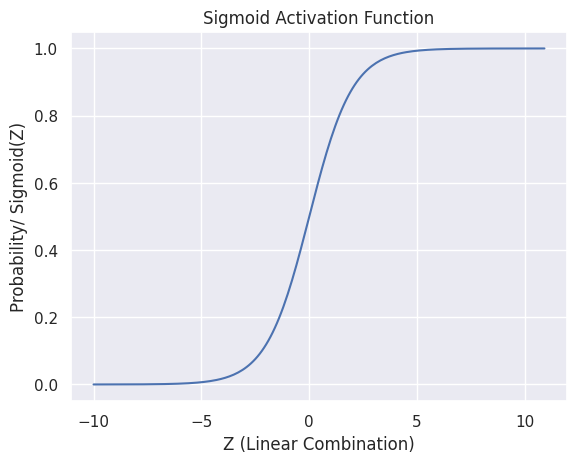

In [5]:
z = np.arange( -10, 11, 0.1 )

sigmoid_values = sigmoid( z )

plt.plot(z, sigmoid_values)

plt.title( "Sigmoid Activation Function" )
plt.xlabel( "Z (Linear Combination)" )
plt.ylabel( "Probability/ Sigmoid(Z)" )
plt.show()

## 3. Making Predictions
We use our weights ($W$) and bias ($b$) to compute $z = W \cdot X + b$, then pass it through the sigmoid function to get probabilities. A threshold (usually 0.5) is used to decide the final class.

**Mathematical Mapping:**
$$z^{(i)} = \mathbf{W} \cdot \mathbf{x}^{(i)} + b$$
$$\hat{y}^{(i)} = g(z^{(i)})$$
$$f(\mathbf{x}^{(i)}) = \begin{cases} 1 & \text{if } \hat{y}^{(i)} \ge \text{threshold} \\ 0 & \text{if } \hat{y}^{(i)} < \text{threshold} \end{cases}$$

In [6]:
w_init = np.array([0.5, -2])
b_init = 0.01

In [7]:
def make_prediction(X, W, b, threshold=0.5):
  """
  Calculates the model output for each example in X.
  """
  m = X.shape[0]
  prob_list = np.zeros((m,))

  for i in range(m):

    # Calculate z = w1*x1 + w2*x2 + ... + b

    z = np.dot(W, X[i]) + b

    # Convert z into a probability

    prob_list[i] = sigmoid(z)

  # If probability > threshold, return True (1), else False (0)

  prediction = (prob_list > threshold)
  return prediction
  # return prob_list

# Test with initial weights
print("Initial Predictions:", make_prediction(X, w_init, b_init))

Initial Predictions: [False  True False  True]


## 4. Cost Function Calculation
To measure model accuracy, we evaluate the system performance across the data using Binary Cross-Entropy Loss (Log Loss).

**Mathematical Formula:**
$$J(\mathbf{W},b) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right]$$

Where $\hat{y}^{(i)} = g(\mathbf{W} \cdot \mathbf{x}^{(i)} + b)$.

In [ ]:
def compute_cost( X, y, W, b ) :

  """Calculates the Mean Squared Error (MSE) to measure model accuracy"""

  m = X.shape[0]
  cost = 0.0

  for i in range( m ) :
    z = np.dot(W, X[i])

    prob = sigmoid(z)

    cost += y[i] * np.log( prob ) + ( ( 1 - y[i] ) * np.log( 1 - prob ) )

  # We divide by m for mathematical convenience in gradient calculations

  cost = cost / ( -m )

  return cost


compute_cost( X, y, w_init, b_init )

np.float64(5.878281054184119)

## 5. Derivative Calculations (Gradients)
We compute the partial derivatives of the cost function $J(\mathbf{W},b)$ with respect to each individual feature weight $w_j$ and the bias $b$.

**Mathematical Formulas:**
$$\frac{\partial J(\mathbf{W},b)}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} \left( \hat{y}^{(i)} - y^{(i)} \right)$$
$$\frac{\partial J(\mathbf{W},b)}{\partial w_j} = \frac{1}{m} \sum_{i=1}^{m} \left( \hat{y}^{(i)} - y^{(i)} \right) x_j^{(i)}$$

In [9]:
def calculate_gradient( X, y, W, b ) :

  m = X.shape[0]
  n = X.shape[1]

  dj_dw = np.zeros((n,))
  dj_db = 0.0

  for i in range(m) :

    z = np.dot(W, X[i]) + b
    prob = sigmoid(z)
    error = prob - y[i]

    dj_db = dj_db +  error

    for j in range(n) :

      dj_dw[j] = dj_dw[j] + ( error * X[i, j] )

  return dj_dw / m, dj_db / m

calculate_gradient( X, y, w_init, b_init )

(array([-5.64305362, -4.18525771]), np.float64(-0.058303660065301105))

## 6. Parameter Updates via Gradient Descent
We systematically update parameters $\mathbf{W}$ and $b$ simultaneously by moving in the negative direction of the gradient scaled by a learning rate $\alpha$.

**Mathematical Update Expressions:**
$$b := b - \alpha \frac{\partial J(\mathbf{W},b)}{\partial b}$$
$$w_j := w_j - \alpha \frac{\partial J(\mathbf{W},b)}{\partial w_j} \quad \text{for } j = 1, 2, \dots, n$$

In [10]:
def gradient_descent( X, y, w_input, b_input, max_iter, alpha = 0.01 ) : # Best value of alpha

  """Automates the tuning of w and b to minimize cost"""

  w = w_input
  b = b_input

  cost_memo = []
  iteration = []

  for i in range(max_iter) :
    # 1. Calculate the gradients (the slope)

    dj_dw, dj_db = calculate_gradient(X, y, w, b)

    # 2. Update parameters by taking a small step (alpha) against the gradient

    w = w - alpha * dj_dw
    b = b - alpha * dj_db


    # 3. Track progress by saving the cost

    cost = compute_cost( X, y, w, b )
    cost_memo.append( cost )
    iteration.append(i)

    # Log the status every 1000 steps
    if i % 1000 == 0 :
      print( f'Iteration : {i}, w : {w}, b : {b:0.4f}, dj_dw : {dj_dw}, dj_db : {dj_db}, cost : {cost:0.4f}' )

  return w, b, cost_memo, iteration

In [11]:
n = X.shape[1]

W_init = np.zeros((n,))
b_init = 0.0

w_final, b_final, cost_memo, iter_list = gradient_descent( X, y, w_input = W_init, b_input = b_init, max_iter = 100000, alpha = 0.01 )

Iteration : 0, w : [0.06875 0.0275 ], b : 0.0000, dj_dw : [-6.875 -2.75 ], dj_db : 0.0, cost : 0.7342
Iteration : 1000, w : [0.02463079 0.17455675], b : -1.5829, dj_dw : [-0.00261172 -0.00382984], dj_db : 0.1239112752429116, cost : 0.7014
Iteration : 2000, w : [0.04614781 0.20697806], b : -2.6027, dj_dw : [-0.00178244 -0.00274424], dj_db : 0.0844250588077729, cost : 0.8699
Iteration : 3000, w : [0.0615091  0.23085018], b : -3.3299, dj_dw : [-0.00133147 -0.0020839 ], dj_db : 0.06300368040659654, cost : 1.0063
Iteration : 4000, w : [0.07335376 0.2494432 ], b : -3.8901, dj_dw : [-0.0010581  -0.00166437], dj_db : 0.05000079099750969, cost : 1.1169
Iteration : 5000, w : [0.08297084 0.26457985], b : -4.3442, dj_dw : [-0.00087672 -0.00138021], dj_db : 0.0413707289851524, cost : 1.2091
Iteration : 6000, w : [0.09106065 0.27731174], b : -4.7257, dj_dw : [-0.00074813 -0.00117686], dj_db : 0.03525502412761029, cost : 1.2880
Iteration : 7000, w : [0.09804087 0.28828507], b : -5.0544, dj_dw : [-0.0

In [12]:
print(w_final)
print(b_final)

[0.22918287 0.49060656]
-11.172459126367531


In [13]:
make_prediction( X, w_final, b_final )

array([False, False,  True,  True])

In [14]:
prediction = make_prediction( X, w_final, b_final ).astype(int)

print(prediction)

[0 0 1 1]
